FOUNDING DATE DISTRIBUTION PLOTS

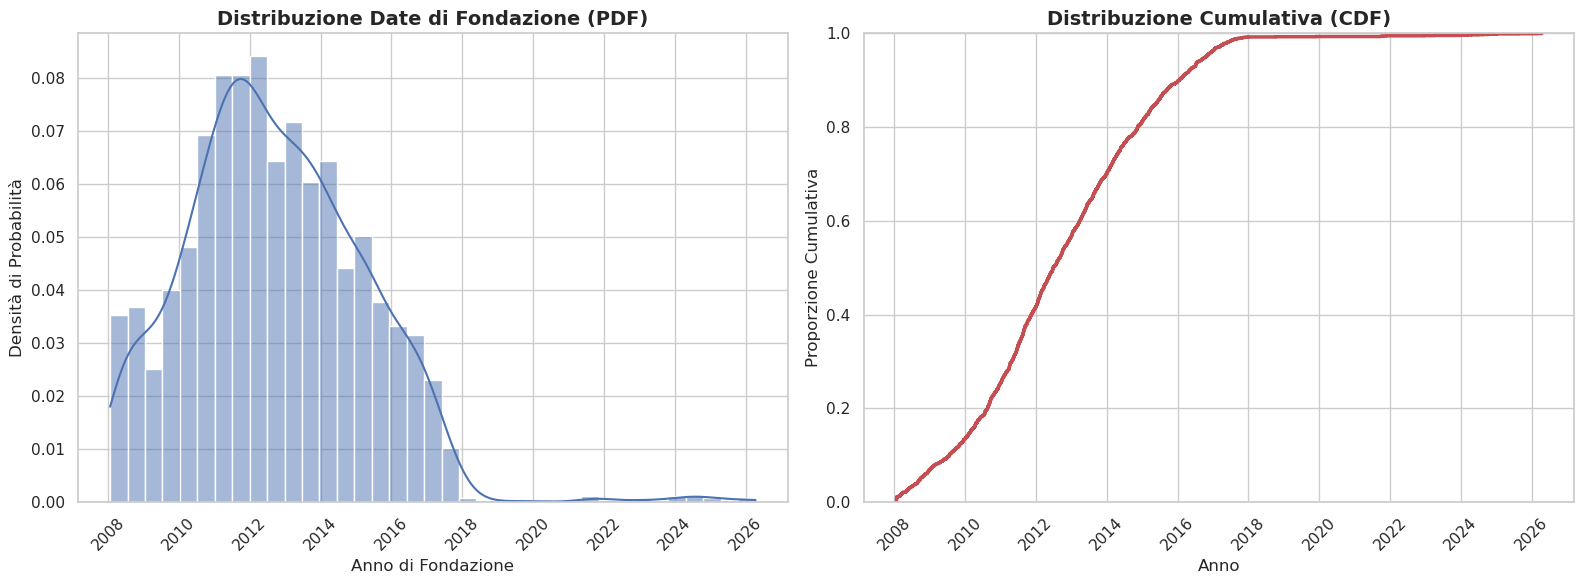

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

file_path = "data/interim/foundersData.csv"
df = pd.read_csv(file_path, index_col=0)

df['subreddit_creation_date'] = pd.to_datetime(df['subreddit_creation_date'], unit='s')

sns.set_theme(style="whitegrid", palette="muted")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Probability Density Function

sns.histplot(data=df, x='subreddit_creation_date', kde=True, stat="probability", ax=axes[0], color="#4C72B0")
axes[0].set_title('Distribuzione Date di Fondazione (PDF)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Anno di Fondazione', fontsize=12)
axes[0].set_ylabel('Densità di Probabilità', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)

# Cumulative Distribution Function

sns.ecdfplot(data=df, x='subreddit_creation_date', ax=axes[1], color="#C44E52", lw=2.5)
axes[1].set_title('Distribuzione Cumulativa (CDF)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Anno', fontsize=12)
axes[1].set_ylabel('Proporzione Cumulativa', fontsize=12)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

LATENCY DISTRIBUTION PLOTS (DAYS BETWEEN FIRST POST AND SUBREDDIT CREATION DATE)

Subreddits with Negative Latency (corrupted data): 4
Subreddits with above a Week of Latency: 781
Subreddits with above a Month of Latency: 598
Subreddits with above 100 Days of Latency: 418
Subreddits with above 500 Days of Latency: 104
Subreddits with above 1000 Days of Latency: 29
Subreddits with above 1500 Days of Latency: 9
Subreddits with above 2000 Days of Latency: 6


Latency Days Data
count    2829.000000
mean       63.048333
std       215.501139
min     -4006.706563
25%         0.002627
50%         0.025069
75%        13.267743
max      2486.030498
Name: latency_days, dtype: float64




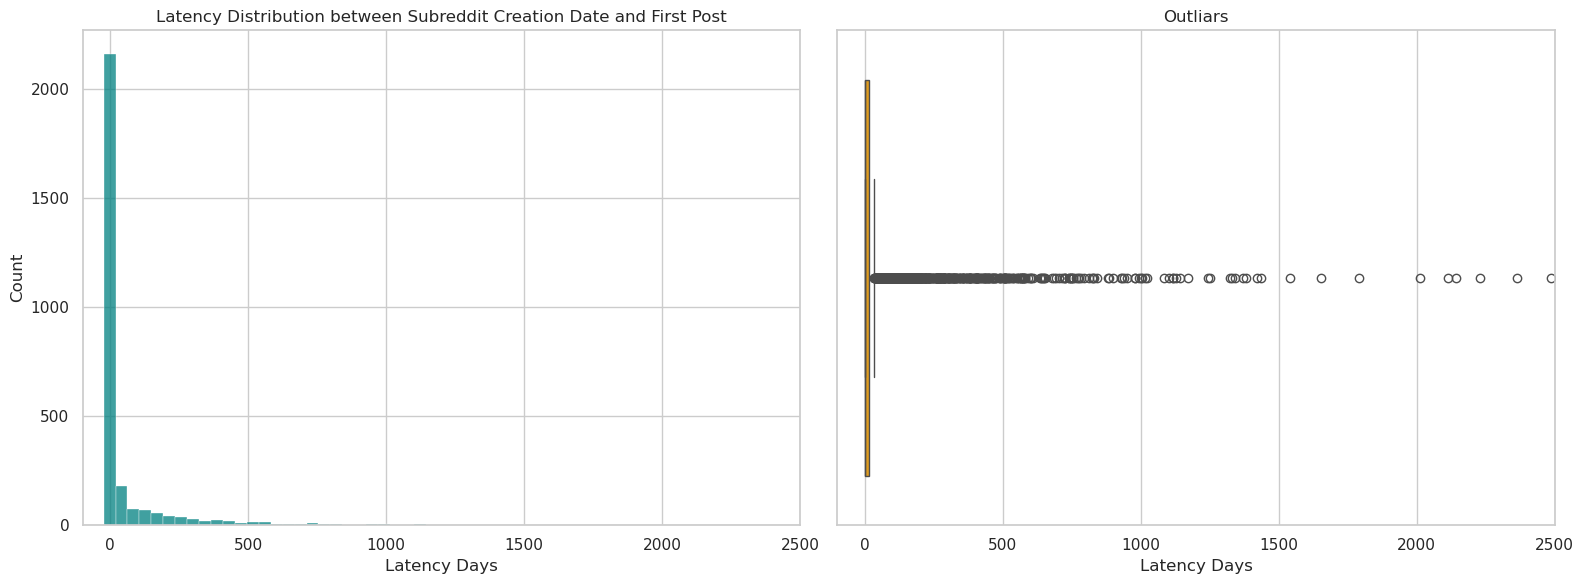

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

founders_data_path = "data/interim/conspiracy_founders_clean.csv"
founders_features_path = "data/interim/founders_features_clean.csv"

founders_data = pd.read_csv(founders_data_path, index_col=0)
founders_features = pd.read_csv(founders_features_path, index_col=0)



founders_data["post_creation_date"] = pd.to_datetime(founders_data["post_creation_date"], unit='s')
founders_data["subreddit_creation_date"] = pd.to_datetime(founders_data["subreddit_creation_date"], unit='s')
founders_features["active since"] = pd.to_datetime(founders_features["active since"], unit='s')

df = pd.merge(founders_data, founders_features, how="inner", on="username")
df.rename(columns={"subreddit_name" : "subredditName"}, inplace=True)

# check latency between subreddit creation and first post
df["latency_days"] = (df["post_creation_date"] - df["subreddit_creation_date"]).dt.total_seconds() / 86400
negative_latency_rows, _ = df[ df["latency_days"] < 0 ].shape
print(f"Subreddits with Negative Latency (corrupted data): {negative_latency_rows}")

# check number of outliars
above_7_latency, _ = df[ df["latency_days"] >= 7 ].shape
above_30_latency, _ = df[ df["latency_days"] >= 30 ].shape
above_100_latency, _ = df[ df["latency_days"] >= 100 ].shape
above_500_latency, _ = df[ df["latency_days"] >= 500 ].shape
above_1000_latency, _ = df[ df["latency_days"] >= 1000 ].shape
above_1500_latency, _ = df[ df["latency_days"] >= 1500 ].shape
above_2000_latency, _ = df[ df["latency_days"] >= 2000 ].shape
print(f"Subreddits with above a Week of Latency: {above_7_latency}\nSubreddits with above a Month of Latency: {above_30_latency}\nSubreddits with above 100 Days of Latency: {above_100_latency}\nSubreddits with above 500 Days of Latency: {above_500_latency}\nSubreddits with above 1000 Days of Latency: {above_1000_latency}\nSubreddits with above 1500 Days of Latency: {above_1500_latency}\nSubreddits with above 2000 Days of Latency: {above_2000_latency}\n\n")
print(f"Latency Days Data\n{df["latency_days"].describe()}\n\n")

# GRAPHS
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(data=df, x="latency_days", ax=axes[0], color="teal", bins=150)
sns.boxplot(data=df, x="latency_days", ax=axes[1], color="orange")

axes[0].set_title("Latency Distribution between Subreddit Creation Date and First Post")
axes[0].set_xlabel("Latency Days")
axes[1].set_title("Outliars")
axes[1].set_xlabel("Latency Days")
axes[1].set_ylabel("")

axes[0].set_xlim(-100,2500)
axes[1].set_xlim(-100, 2500)

plt.tight_layout()
plt.show()

FOUNDERS SENIORITY PLOT

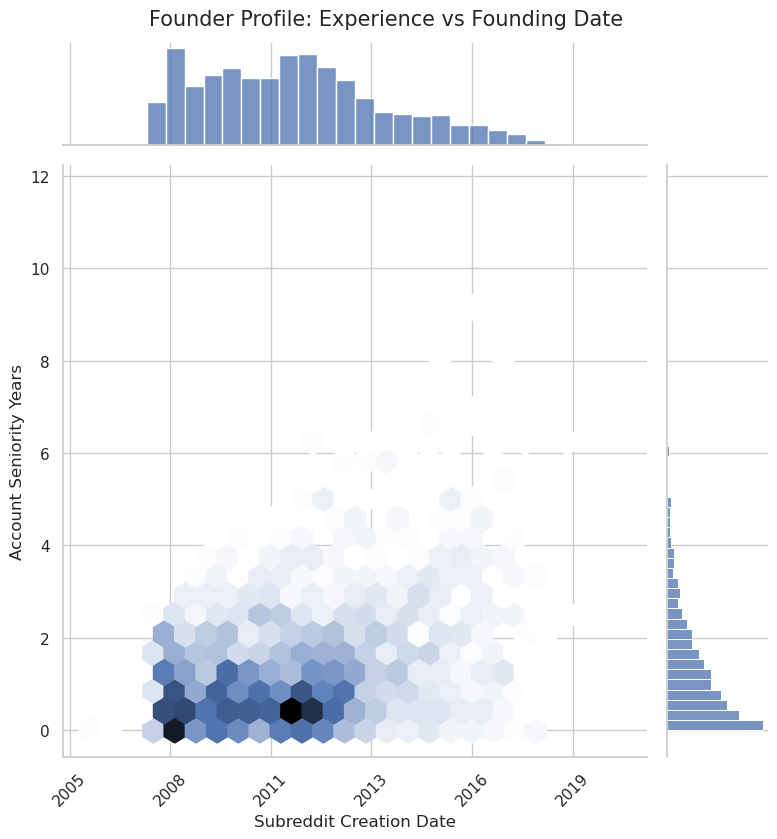

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

founders_data_path = "data/interim/conspiracy_founders_clean.csv"
founders_features_path = "data/interim/founders_features_clean.csv"

founders_data = pd.read_csv(founders_data_path, index_col=0)
founders_features = pd.read_csv(founders_features_path, index_col=0)

founders_data["post_creation_date"] = pd.to_datetime(founders_data["post_creation_date"], unit='s')
founders_data["subreddit_creation_date"] = pd.to_datetime(founders_data["subreddit_creation_date"], unit='s')
founders_features["active since"] = pd.to_datetime(founders_features["active since"], unit='s')

df = pd.merge(founders_data, founders_features, how="inner", on="username")
df.rename(columns={"name" : "subredditName"}, inplace=True)


df["account_seniority_years"] = (df["subreddit_creation_date"] - df["active since"]).dt.total_seconds() / (86400 * 365)
df_insight = df[df["account_seniority_years"] >= 0].copy()

df_insight['date_numeric'] = mdates.date2num(df_insight['subreddit_creation_date'])

g = sns.jointplot(
    data=df_insight, 
    x="date_numeric", 
    y="account_seniority_years",
    kind="hex", 
    color="#4C72B0",
    height=8,
    gridsize=25,
    joint_kws={"mincnt":1}
)

g.ax_joint.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.setp(g.ax_joint.get_xticklabels(), rotation=45)

g.fig.suptitle("Founder Profile: Experience vs Founding Date", y=1.02, fontsize=15)
g.set_axis_labels("Subreddit Creation Date", "Account Seniority Years", fontsize=12)

plt.show()

MATCHING FEATURES DISTRIBUTION PLOTS

count    2248.000000
mean      278.745552
std       256.227993
min         0.000000
25%        99.000000
50%       208.000000
75%       374.250000
max      2776.000000
Name: num subreddits, dtype: float64


count    2.248000e+03
mean     2.534542e+05
std      1.124131e+07
min      3.000000e+00
25%      1.409500e+03
50%      4.188000e+03
75%      1.045825e+04
max      5.328416e+08
Name: num contributions, dtype: float64




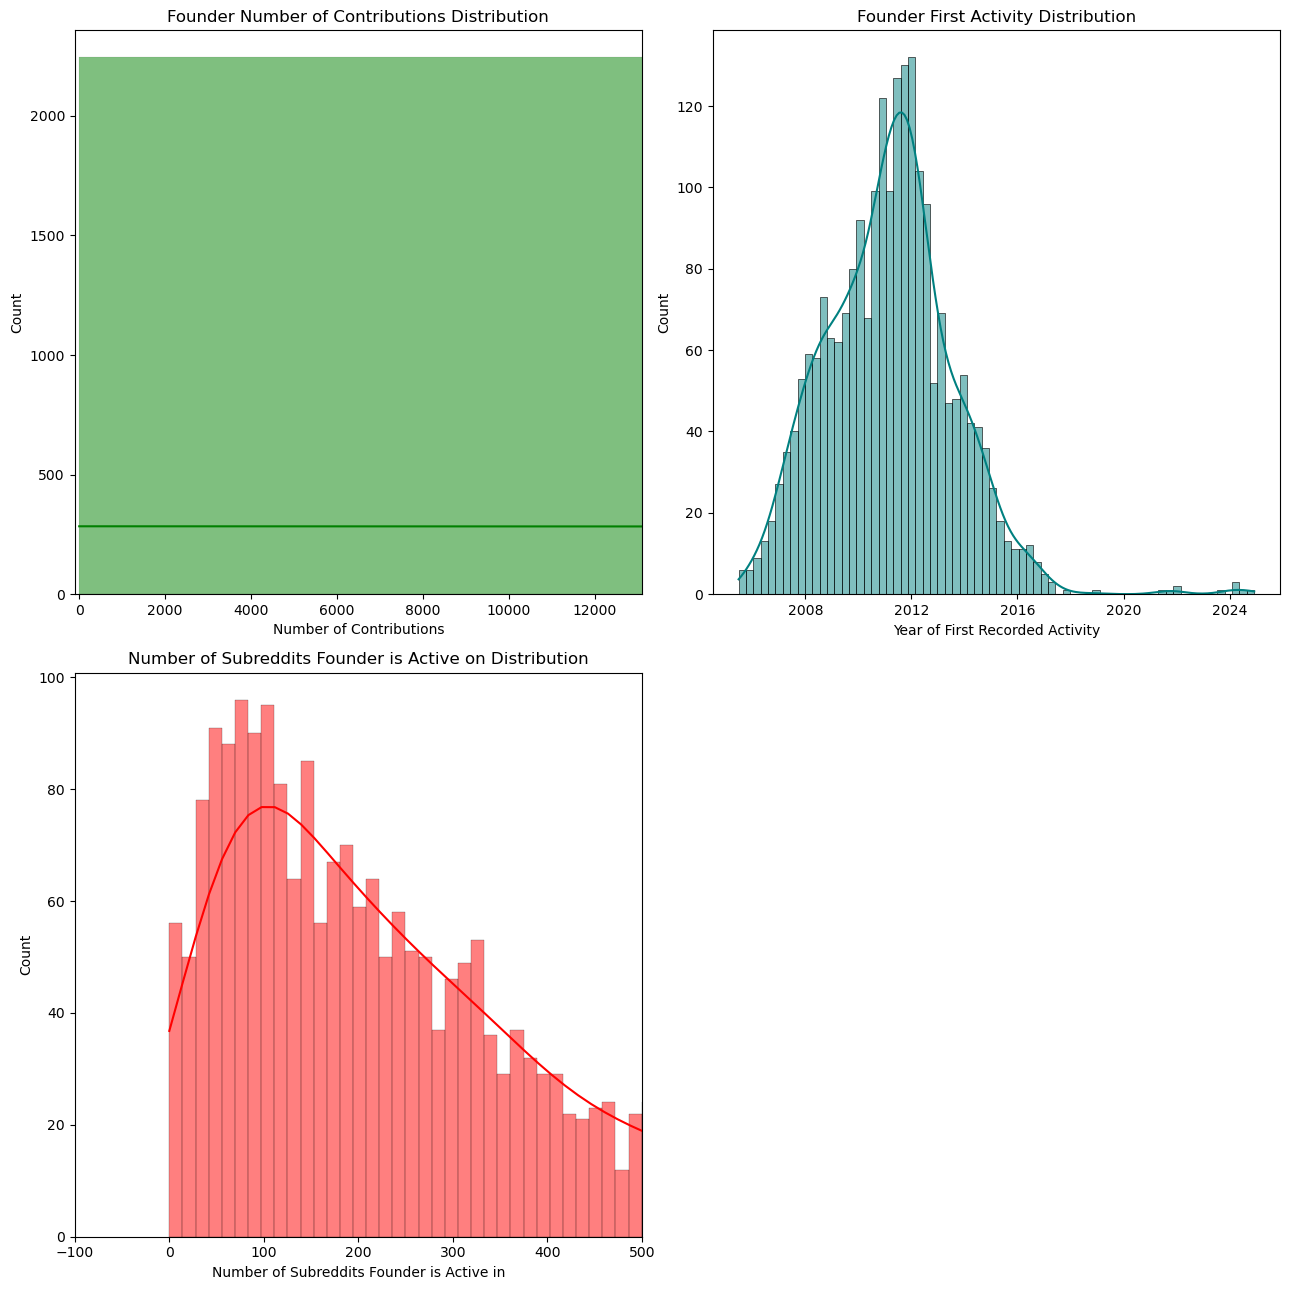

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

df = pd.read_csv("../data/interim/foundersFeatures_FINAL.csv", index_col=0)
df["active since"] = pd.to_datetime(df["active since"], unit='s')
df["subreddits"] = df["subreddits"].apply(ast.literal_eval)
df["num subreddits"] = df["subreddits"].apply(len)
print(df["num subreddits"].describe())
print("\n")
print(df["num contributions"].describe())
print("\n")

fig, axes = plt.subplots(2, 2, figsize=(13,13))
axes[1, 1].set_visible(False)
sns.histplot(data=df, x="num contributions", kde=True, ax=axes[0][0], bins=700, color="green")
sns.histplot(data=df, x="active since", kde=True, ax=axes[0][1], bins=70, color="teal")
sns.histplot(data=df, x="num subreddits", kde=True, ax=axes[1][0], bins=200, color="red")

axes[0][0].set_xlim(-100,13100)
axes[1][0].set_xlim(-100,500)

axes[0][0].set_title("Founder Number of Contributions Distribution")
axes[0][0].set_xlabel("Number of Contributions")
axes[0][1].set_title("Founder First Activity Distribution")
axes[0][1].set_xlabel("Year of First Recorded Activity")
axes[1][0].set_title("Number of Subreddits Founder is Active on Distribution")
axes[1][0].set_xlabel("Number of Subreddits Founder is Active in")

plt.tight_layout()
plt.show()

In [14]:
import pandas as pd
import numpy as np

# =====================================================================
# 1. CARICAMENTO E VERIFICA DI INTEGRITÀ RIGHE
# =====================================================================
df_data = pd.read_csv("/home/andri/conspiracy-founders/data/interim/foundersData_FINAL.csv")
df_feat = pd.read_csv("/home/andri/conspiracy-founders/data/interim/foundersFeatures_FINAL.csv")

print("--- VERIFICA INTEGRITÀ INPUT ---")
print(f"Righe in foundersData (ufficiali):         {len(df_data)}")
print(f"Righe in foundersFeatures (estratte):      {len(df_feat)}")

# Usiamo 'how=left' per preservare la struttura di foundersData. Se un utente non ha le feature,
# vedremo dei NaN anziché perdere la riga silenziosamente.
df = pd.merge(df_data, df_feat, left_on='founder', right_on='username', how='left')
print(f"Righe totali post-merge:                   {len(df)}")

if len(df) != len(df_data):
    print("⚠️ WARNING: Il merge ha modificato il numero di righe originarie! Controlla i dati.")
print("\n")

# =====================================================================
# 2. DEFINIZIONE DELLE COSTANTI TEMPORALI (UNIX SECONDS AUDIT)
# =====================================================================
# 1 Minuto = 60 secondi
# 1 Ora    = 60 * 60 = 3.600 secondi
# 1 Giorno = 24 * 3.600 = 86.400 secondi
# 1 Mese   = 30 Giorni = 30 * 86.400 = 2.592.000 secondi
# 6 Mesi   = 6 * 2.592.000 = 15.552.000 secondi

ONE_MONTH_SECONDS = 30 * 24 * 60 * 60
SIX_MONTHS_SECONDS = 6 * ONE_MONTH_SECONDS

# =====================================================================
# 3. CALCOLO DELLE METRICHE TEMPORALI
# =====================================================================
# Calcolo mesi passati tra iscrizione a Reddit (active since) e creazione sub (subreddit_creation_date)
# .clip(lower=0) protegge da anomalie API in cui active_since potrebbe risultare temporalmente successivo
df['months_before_founding'] = ((df['subreddit_creation_date'] - df['active since']) / ONE_MONTH_SECONDS).clip(lower=0)

# Calcolo mesi di storico reali disponibili escludendo i 6 mesi di sbarramento (Pre-Obs)
df['months_before_pre_obs'] = (((df['subreddit_creation_date'] - SIX_MONTHS_SECONDS) - df['active since']) / ONE_MONTH_SECONDS).clip(lower=0)


# =====================================================================
# CONTROLLO 1: REQUISITO ANZIANITÀ MINIMA AL MOMENTO DEL FOUNDING
# =====================================================================
utenti_anziani_al_founding = df[df['months_before_founding'] >= 12]
percentuale_anziani = (len(utenti_anziani_al_founding) / len(df)) * 100

print("--- CONTROLLO 1: REQUISITO 1 ANNO ALLA FONDAZIONE ---")
print(f"Utenti attivi da ALMENO 1 ANNO quando hanno fondato il sub: {len(utenti_anziani_al_founding)} su {len(df)} ({percentuale_anziani:.1f}%)")
print(f"Anzianità media al momento del founding event: {df['months_before_founding'].mean():.1f} mesi\n")


# =====================================================================
# CONTROLLO 2: DISCRECRETIZZAZIONE IN BIN (BREAKDOWN RICHIESTO)
# =====================================================================
# I confini dei bin: [0, 3] include lo 0; (3, 6] include fino a 6; ... fino a infinito
bins = [0, 3, 6, 9, 12, np.inf]
labels = ['0 - 3 mesi', '3 - 6 mesi', '6 - 9 mesi', '9 - 12 mesi', 'Oltre 12 mesi']

# include_lowest=True è fondamentale per far cadere lo 0 spaccato dentro il primo bin [0, 3]
df['founding_intervals'] = pd.cut(df['months_before_founding'], bins=bins, labels=labels, include_lowest=True)

# Calcolo frequenze assolute e percentuali
counts = df['founding_intervals'].value_counts().sort_index()
percentages = df['founding_intervals'].value_counts(normalize=True).sort_index() * 100
nans_count = df['months_before_founding'].isna().sum()

print("--- CONTROLLO 2: DISTRIBUZIONE FASCE DI ANZIANITÀ (PRE-FOUNDING) ---")
print(f"{'Intervallo Temporale':<22} | {'Conteggio Utenti':<16} | {'Percentuale':<12}")
print("-" * 59)
for label in labels:
    cnt = counts.get(label, 0)
    pct = percentages.get(label, 0.0)
    print(f"{label:<22} | {cnt:<16} | {pct:.1f}%")

if nans_count > 0:
    print(f"{'Dati Mancanti (NaN)':<22} | {nans_count:<16} | {(nans_count/len(df))*100:.1f}%")
print("-" * 59)
print(f"{'TOTALE VERIFICATO':<22} | {counts.sum() + nans_count:<16} | 100.0%\n")


# =====================================================================
# CONTROLLO 3: VALIDAZIONE DEL COHORT DI STORICO PER IL MATCHING (PRE-OBS)
# =====================================================================
print("--- CONTROLLO 3: STORICO REALE DISPONIBILE PER IL MATCHING ---")
print("Statistiche descrittive dello storico puro (mesi) prima del cutoff dei 6 mesi:")
print(df['months_before_pre_obs'].describe())

# Identifichiamo gli utenti strutturalmente privi di passato utile (iscritti a Reddit meno di 6 mesi prima dell'evento)
zero_storico = df[df['months_before_pre_obs'] == 0]
percentuale_zero = (len(zero_storico) / len(df)) * 100

print(f"\nUtenti con 0 mesi di storico prima della pre-obs: {len(zero_storico)} su {len(df)} ({percentuale_zero:.1f}%)")
print("🚨 Verifica incrociata matematica:")
print(f" -> Somma dei bin '0-3 mesi' e '3-6 mesi' del Controllo 2: {counts.get('0 - 3 mesi', 0) + counts.get('3 - 6 mesi', 0)} utenti.")
print(f" -> Utenti rilevati a zero storico nel Controllo 3:          {len(zero_storico)} utenti.")

if (counts.get('0 - 3 mesi', 0) + counts.get('3 - 6 mesi', 0)) == len(zero_storico):
    print(" Verificato: I due motori di calcolo coincidono al millisecondo. Calcoli validati!")
else:
    print("⚠️ ATTENZIONE: Discrepanza nei conteggi. Controlla se ci sono valori esattamente pari a 6 mesi (6.0).")

--- VERIFICA INTEGRITÀ INPUT ---
Righe in foundersData (ufficiali):         2248
Righe in foundersFeatures (estratte):      2248
Righe totali post-merge:                   2248


--- CONTROLLO 1: REQUISITO 1 ANNO ALLA FONDAZIONE ---
Utenti attivi da ALMENO 1 ANNO quando hanno fondato il sub: 1250 su 2248 (55.6%)
Anzianità media al momento del founding event: 19.2 mesi

--- CONTROLLO 2: DISTRIBUZIONE FASCE DI ANZIANITÀ (PRE-FOUNDING) ---
Intervallo Temporale   | Conteggio Utenti | Percentuale 
-----------------------------------------------------------
0 - 3 mesi             | 313              | 13.9%
3 - 6 mesi             | 231              | 10.3%
6 - 9 mesi             | 229              | 10.2%
9 - 12 mesi            | 225              | 10.0%
Oltre 12 mesi          | 1250             | 55.6%
-----------------------------------------------------------
TOTALE VERIFICATO      | 2248             | 100.0%

--- CONTROLLO 3: STORICO REALE DISPONIBILE PER IL MATCHING ---
Statistiche descr